# ICT-15l — Indépendance au générateur de nouveauté : le relief b1 survit-il au contrôle de dimension ?

[↑ ICT-Series](../README.md)

**Substrat :** Axelrod régénéré.
**Discriminant nerf/b1 :** [ICT-15j](./ICT-15j-NerveDiscriminant-Python.ipynb).

## Cadrage

### Question et hypothèse

Sur l’Axelrod régénéré, ICT-15j mesure `b1_max_persistence = 0,3989` pour une population agent-based en sélection-mutation (graine 20260720), contre `0,0000` pour la baseline réplicateur dégénérée. Le relief pourrait signaler une nouveauté stratégique; mais le mécanisme qui injecte la nouveauté peut aussi avoir inscrit ce relief dans la géométrie du générateur. Le test demande donc si le relief survit à deux générateurs structurellement distincts et au contrôle négatif de dimension.

## Protocole pré-enregistré

1. Comparer deux générateurs de nouveauté : réensemencement uniforme dans un catalogue fermé et dérive comportementale par mutation de bits d’un génome (vocabulaire ouvert).
2. Construire un contrôle négatif de dimension : doubler les étiquettes du simplexe sans ajouter de comportement nouveau, en donnant deux noms à chaque stratégie. Si ce contrôle produit aussi du relief, le discriminant peut mesurer la dimension ou le turnover plutôt que la nouveauté.
3. Apparier substrat IPD, bruit, taille de population, longueur de trajectoire, taux de mutation et graines entre régimes.
4. Appliquer le verdict pré-enregistré programmaticalement.

Avec `relief(r)` égal à la moyenne de `b1_max_persistence` sur trois graines et `τ = 0,05` (constante `TAU`, tolérance du verdict ICT-15j) :

| Condition | Verdict |
|---|---|
| `relief(R1) > τ`, `relief(R2) > τ` et `relief(R3) ≤ τ` | `ROBUSTE_AU_GENERATEUR` |
| exactement un de `relief(R1)`, `relief(R2)` est `> τ` (avec `R0 ≤ τ`) | `ARTEFACT_DE_GENERATEUR` |
| `relief(R3) > τ` | `CONFONDU_AVEC_LA_DIMENSION` |
| aucun des cas ci-dessus | `INCONCLUSIVE` |

La règle est appliquée programmatiquement en §6; le verdict imprimé est calculé, jamais saisi à la main.

## Discipline

### Portée

Quel que soit le verdict, aucune promotion en « loi ICT » n’est justifiée par cette expérience seule : elle relève d’une validation externe. La mesure reste descriptive, soit le nombre de classes H¹ persistantes dans le nerf simplicial sur les sections locales des proxys; l’objet n’est pas nommé phénoménologiquement.

> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md) ne concerne ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

In [1]:
// Imports + recette observable, REPLIQUE EXACTE d'ICT-15j (cellules f22b81e8/ff929034)
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;

// Le carnet utilise C=1 pour compter les coups, tandis que le module IPD utilise C=0.
const int C = 1, D = 0;

public sealed class IctRandom
{
    private ulong state;
    public IctRandom(int seed) { state = (ulong)(uint)seed; if (state == 0) state = 0x9e3779b97f4a7c15UL; }
    public ulong Next64() { unchecked { ulong x = state; x ^= x >> 12; x ^= x << 25; x ^= x >> 27; state = x; return x * 2685821657736338717UL; } }
    public double NextDouble() => (Next64() >> 11) * (1.0 / 9007199254740992.0);
    public int NextInt(int n) => (int)(NextDouble() * n);
}

public static class IctObservable
{
    // Valeurs propres d'une matrice symétrique réelle par rotations de Jacobi.
    public static double[] Eigenvalues(double[,] matrix)
    {
        int n = matrix.GetLength(0);
        var a = (double[,])matrix.Clone();
        for (int iter = 0; iter < 10000; iter++)
        {
            int p = 0, q = 1; double largest = 0;
            for (int i = 0; i < n; i++)
                for (int j = i + 1; j < n; j++)
                    if (Math.Abs(a[i,j]) > largest) { largest = Math.Abs(a[i,j]); p = i; q = j; }
            if (largest < 1e-14) break;
            double angle = 0.5 * Math.Atan2(2 * a[p,q], a[q,q] - a[p,p]);
            double c = Math.Cos(angle), s = Math.Sin(angle);
            double app = a[p,p], aqq = a[q,q], apq = a[p,q];
            for (int k = 0; k < n; k++)
            {
                if (k == p || k == q) continue;
                double akp = a[k,p], akq = a[k,q];
                a[k,p] = a[p,k] = c * akp - s * akq;
                a[k,q] = a[q,k] = s * akp + c * akq;
            }
            a[p,p] = c*c*app - 2*s*c*apq + s*s*aqq;
            a[q,q] = s*s*app + 2*s*c*apq + c*c*aqq;
            a[p,q] = a[q,p] = 0;
        }
        return Enumerable.Range(0, n).Select(i => a[i,i]).OrderBy(x => x).ToArray();
    }

    public static double[] Proxies(int[] states, int n)
    {
        // TPM lissée pour le spectre ; adjacence observée pour les sensibilités.
        var p = new double[n,n];
        for (int i = 0; i < n; i++) for (int j = 0; j < n; j++) p[i,j] = 1e-9;
        for (int i = 0; i + 1 < states.Length; i++) p[states[i], states[i+1]] += 1;
        for (int i = 0; i < n; i++)
        {
            double sum = 0; for (int j = 0; j < n; j++) sum += p[i,j];
            for (int j = 0; j < n; j++) p[i,j] /= sum;
        }
        var lap = new double[n,n];
        for (int i = 0; i < n; i++) for (int j = i + 1; j < n; j++)
        {
            double w = (p[i,j] + p[j,i]) / 2;
            lap[i,j] = lap[j,i] = -w; lap[i,i] += w; lap[j,j] += w;
        }
        var eigen = Eigenvalues(lap);
        var ids = new Dictionary<int,int>();
        var encoded = new int[states.Length];
        for (int i = 0; i < states.Length; i++)
        {
            if (!ids.ContainsKey(states[i])) ids[states[i]] = ids.Count;
            encoded[i] = ids[states[i]];
        }
        var adjacency = new bool[n,n];
        for (int i = 0; i + 1 < encoded.Length; i++)
        {
            int a = encoded[i], b = encoded[i+1];
            if (a != b) adjacency[a,b] = adjacency[b,a] = true;
        }
        var degrees = new double[ids.Count];
        for (int i = 0; i < degrees.Length; i++) for (int j = 0; j < n; j++) if (adjacency[i,j]) degrees[i]++;
        return new[] { eigen[1] - eigen[0], degrees.Length == 0 ? 0 : degrees.Average(), degrees.Length == 0 ? 0 : degrees.Max() };
    }

    public static double Quantile(double[] sorted, double probability)
    {
        double position = (sorted.Length - 1) * probability;
        int lo = (int)Math.Floor(position), hi = (int)Math.Ceiling(position);
        return sorted[lo] + (sorted[hi] - sorted[lo]) * (position - lo);
    }

    public sealed class Simplex
    {
        public int A, B, C, Dim;
        public double Filtration;
        public Simplex(int a, int b, int c, int dim, double filtration) { A=a; B=b; C=c; Dim=dim; Filtration=filtration; }
    }

    public static double MaxPersistence(double[,] points)
    {
        // Filtration Rips complète : réduction des frontières sur F2 jusqu'aux triangles.
        int n = points.GetLength(0), d = points.GetLength(1);
        var normalized = new double[n,d];
        for (int j = 0; j < d; j++)
        {
            double mean = 0; for (int i = 0; i < n; i++) mean += points[i,j]; mean /= n;
            double variance = 0; for (int i = 0; i < n; i++) variance += (points[i,j]-mean)*(points[i,j]-mean);
            double std = Math.Sqrt(variance/n); if (std <= 1e-12) std = 1;
            for (int i = 0; i < n; i++) normalized[i,j] = (points[i,j]-mean)/std;
        }
        var dist = new double[n,n];
        for (int i = 0; i < n; i++) for (int j = i+1; j < n; j++)
        {
            double sum = 0; for (int k = 0; k < d; k++) { double x = normalized[i,k]-normalized[j,k]; sum += x*x; }
            dist[i,j] = dist[j,i] = Math.Sqrt(sum);
        }
        var simplices = new List<Simplex>();
        for (int i = 0; i < n; i++) simplices.Add(new Simplex(i,-1,-1,0,0));
        for (int i = 0; i < n; i++) for (int j = i+1; j < n; j++) simplices.Add(new Simplex(i,j,-1,1,dist[i,j]));
        for (int i = 0; i < n; i++) for (int j = i+1; j < n; j++) for (int k = j+1; k < n; k++)
            simplices.Add(new Simplex(i,j,k,2,Math.Max(dist[i,j],Math.Max(dist[i,k],dist[j,k]))));
        simplices = simplices.OrderBy(s => s.Filtration).ThenBy(s => s.Dim).ThenBy(s => s.A).ThenBy(s => s.B).ThenBy(s => s.C).ToList();
        var lookup = new Dictionary<(int,int,int),int>();
        for (int i = 0; i < simplices.Count; i++) { var s = simplices[i]; lookup[(s.A,s.B,s.C)] = i; }
        var reduced = new Dictionary<int,HashSet<int>>();
        double maximum = 0;
        for (int j = 0; j < simplices.Count; j++)
        {
            var s = simplices[j]; var column = new HashSet<int>();
            if (s.Dim == 1) { column.Add(lookup[(s.A,-1,-1)]); column.Add(lookup[(s.B,-1,-1)]); }
            if (s.Dim == 2) { column.Add(lookup[(s.A,s.B,-1)]); column.Add(lookup[(s.A,s.C,-1)]); column.Add(lookup[(s.B,s.C,-1)]); }
            while (column.Count > 0)
            {
                int pivot = column.Max();
                if (!reduced.TryGetValue(pivot, out var previous))
                {
                    reduced[pivot] = column;
                    if (s.Dim == 2) maximum = Math.Max(maximum, s.Filtration - simplices[pivot].Filtration);
                    break;
                }
                column.SymmetricExceptWith(previous);
            }
        }
        return maximum;
    }

    public static (double b1, int symbols) CoopToB1(double[] coop, string name, int nSymbols = 8)
    {
        var sorted = coop.OrderBy(x => x).ToArray();
        var cuts = Enumerable.Range(1,nSymbols-1).Select(i => Quantile(sorted,(double)i/nSymbols)).ToArray();
        var states = coop.Select(x => cuts.Count(q => x >= q)).ToArray();
        var values = new List<double>[] { new List<double>(), new List<double>(), new List<double>() };
        for (int w = 0; w < 30; w++)
        {
            int start = w * states.Length / 30;
            int end = Math.Max(start+2,(w+1)*states.Length/30);
            var chunk = states.Skip(start).Take(end-start).ToArray();
            if (chunk.Length < 2) chunk = states.Skip(start).Take(4).ToArray();
            try { var p = Proxies(chunk,nSymbols); for (int j=0;j<3;j++) values[j].Add(p[j]); }
            catch { for (int j=0;j<3;j++) values[j].Add(double.NaN); }
        }
        var points = new double[30,3];
        for (int j=0;j<3;j++)
        {
            var valid = values[j].Where(x => !double.IsNaN(x) && !double.IsInfinity(x)).ToArray();
            for (int i=0;i<valid.Length && i<30;i++) points[i,j] = valid[i];
        }
        return (MaxPersistence(points), states.Distinct().Count());
    }
}

// Six stratégies du module stratégique : C=0 et D=1.
public static class IctIpd
{
    public static int Play(int strategy, List<int> own, List<int> opp, IctRandom rng)
    {
        if (strategy == 0) return 0;
        if (strategy == 1) return 1;
        if (strategy == 2) return opp.Count == 0 ? 0 : opp[opp.Count-1];
        if (strategy == 3) return opp.Count == 0 || opp[opp.Count-1] == 0 || rng.NextDouble() < 1.0/3.0 ? 0 : 1;
        if (strategy == 4)
        {
            if (own.Count == 0) return 0;
            int a=own[own.Count-1], b=opp[opp.Count-1];
            return Payoff(a,b) >= 3 ? a : 1-a;
        }
        return opp.Contains(1) ? 1 : 0;
    }
    public static double Payoff(int a, int b) => a == 0 ? (b == 0 ? 3 : 0) : (b == 0 ? 5 : 1);
}

(double b1, int symbols) coop_to_b1(double[] coop, string name, int n_symbols = 8) => IctObservable.CoopToB1(coop, name, n_symbols);
Console.WriteLine("recette observable chargee (replique ICT-15j).");

recette observable chargee (replique ICT-15j).


## 1. Les quatre régimes et leur appariement

| régime | mécanisme | vocabulaire | dimension du simplexe | nouveauté |
|---|---|---|---|---|
| **R0** | replicateur-mutation **déterministe** (`replicator_mutation_trajectory`) | fermé (6 stratégies) | 6 | aucune (bruit uniforme `mu/n`) |
| **R1** | agent-based Wright-Fisher, **resemencement uniforme** (`evolve_population`, #12673) | fermé (6 stratégies) | 6 | turnover de composition (catalogue fermé) |
| **R2** | agent-based, **dérive comportementale** : génomes 5 bits, mutation par inversion de bit | **ouvert** (32 comportements possibles) | croît avec les mutants | comportements **nouveaux** hors catalogue initial |
| **R3** | agent-based Wright-Fisher, étiquettes **dupliquées par blocs** (6 comportements × 2 noms) | fermé (mêmes 6 comportements) | **12** | **aucune** (contrôle négatif) |

Ce que chaque générateur fait au vocabulaire :
- **R1** tire les mutants **uniformément dans un catalogue fixe** — un type absent peut réapparaître,
  mais aucun comportement nouveau n'existe ;
- **R2** mute **localement le code d'un comportement existant** (1 bit du génome) — les mutants
  sont des variantes de voisins, et la plupart n'existaient pas dans la population initiale ;
- **R3** double les étiquettes sans toucher aux comportements — la dimension du simplexe monte
  de 6 à 12, la distribution de mutation sur les **comportements** est inchangée.

**Appariement** (montré, pas affirmé — imprimé par la cellule suivante) : même substrat IPD
canonique, même bruit d'exécution `noise = 0.02`, `pop = 60`, `n_generations = 400`,
`n_rounds = 30`, `mutation_rate = 0.05`, graines `[20260720, 42, 7]` **identiques entre régimes**.
R0 est le régime déterministe (champ moyen) : l'appariement porte sur ses parties stochastiques
(construction de la matrice de gains, estimation de la coopération sous bruit).

In [2]:
// Constantes appariées -- identiques pour les quatre régimes
var SEEDS = new[] { 20260720, 42, 7 };
const int POP = 60, GENS = 400, ROUNDS = 30;
const double NOISE = 0.02, MU = 0.05;
const double TAU = 0.05;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;
Console.WriteLine("=== Protocole d'appariement (commun aux 4 regimes) ===");
Console.WriteLine("  substrat            : IPD canonique (payoff_pair de ict.strategic_morphodynamics)");
Console.WriteLine(FormattableString.Invariant($"  bruit d'execution   : noise = {NOISE}"));
Console.WriteLine(FormattableString.Invariant($"  population          : {POP} agents (R0 : champ moyen, pas d'agents)"));
Console.WriteLine(FormattableString.Invariant($"  generations/pas     : {GENS}"));
Console.WriteLine(FormattableString.Invariant($"  rounds par match    : {ROUNDS}"));
Console.WriteLine(FormattableString.Invariant($"  taux de mutation    : {MU}"));
Console.WriteLine($"  graines             : [{string.Join(", ", SEEDS)}] (identiques entre regimes)");
Console.WriteLine("  observable          : coop -> 8 symboles (quantiles) -> 30 fenetres x 3 proxys -> b1");
Console.WriteLine(FormattableString.Invariant($"  seuil de verdict    : tau = {TAU}"));

=== Protocole d'appariement (commun aux 4 regimes) ===


  substrat            : IPD canonique (payoff_pair de ict.strategic_morphodynamics)


  bruit d'execution   : noise = 0.02


  population          : 60 agents (R0 : champ moyen, pas d'agents)


  generations/pas     : 400


  rounds par match    : 30


  taux de mutation    : 0.05


  graines             : [20260720, 42, 7] (identiques entre regimes)


  observable          : coop -> 8 symboles (quantiles) -> 30 fenetres x 3 proxys -> b1


  seuil de verdict    : tau = 0.05


## 2. R0 — replicateur-mutation déterministe (vocabulaire fermé)

Dynamique de champ moyen `x(t+1) = (1-mu) * x(t) * f(t)/<f>(t) + mu/n` sur la matrice de
gains du substrat. La trajectoire converge vers l'équilibre mutation-sélection et s'y fige :
c'est le régime « mutation uniforme » de la table de #13308, attendu à relief nul.
Le taux de coopération est mesuré **comme dans les régimes agent-based** : par une matrice
empirique de coopération `C_ij` (paires jouées sous le même bruit), puis
`coop(t) = x(t)^T C x(t)`.

In [3]:
// R0 : réplicateur-mutation déterministe et coopération empirique sous bruit.
double[] regime_r0(int seed)
{
    var rng = new IctRandom(seed);
    const int n = 6;
    var gains = new double[n,n];
    // La matrice de gains source utilise 3 répétitions de 200 coups sans bruit.
    for (int i=0;i<n;i++) for (int j=0;j<n;j++)
    {
        double total = 0;
        for (int rep=0;rep<3;rep++)
        {
            var own = new List<int>(); var opp = new List<int>(); double score=0;
            for (int t=0;t<200;t++)
            {
                int a=IctIpd.Play(i,own,opp,rng), b=IctIpd.Play(j,opp,own,rng);
                score += IctIpd.Payoff(a,b); own.Add(a); opp.Add(b);
            }
            total += score/200.0;
        }
        gains[i,j] = total/3.0;
    }
    var trajectory = new double[GENS+1,n];
    var x = Enumerable.Repeat(1.0/n,n).ToArray();
    for (int i=0;i<n;i++) trajectory[0,i]=x[i];
    for (int t=0;t<GENS;t++)
    {
        var fitness = new double[n];
        for (int i=0;i<n;i++) for (int j=0;j<n;j++) fitness[i] += gains[i,j]*x[j];
        double average=0; for (int i=0;i<n;i++) average += fitness[i]*x[i];
        if (average < 1e-12) break;
        for (int i=0;i<n;i++) x[i]=(1-MU)*x[i]*fitness[i]/average+MU/n;
        double sum=x.Sum(); if (sum>1e-12) for (int i=0;i<n;i++) x[i]/=sum;
        for (int i=0;i<n;i++) trajectory[t+1,i]=x[i];
    }
    // Les appels directs aux stratégies partagent le générateur utilisé pour le bruit.
    var cooperation = new double[n,n];
    for (int i=0;i<n;i++) for (int j=0;j<n;j++)
    {
        double count=0;
        for (int rep=0;rep<20;rep++)
        {
            var own=new List<int>(); var opp=new List<int>();
            for (int t=0;t<ROUNDS;t++)
            {
                int a=IctIpd.Play(i,own,opp,rng), b=IctIpd.Play(j,opp,own,rng);
                if (NOISE>0) { if (rng.NextDouble()<NOISE) a=1-a; if (rng.NextDouble()<NOISE) b=1-b; }
                own.Add(a); opp.Add(b);
                count += (a==C ? 1 : 0) + (b==C ? 1 : 0);
            }
        }
        cooperation[i,j]=count/(2.0*20*ROUNDS);
    }
    var result=new double[GENS+1];
    for (int t=0;t<=GENS;t++) for (int i=0;i<n;i++) for (int j=0;j<n;j++)
        result[t] += trajectory[t,i]*cooperation[i,j]*trajectory[t,j];
    return result;
}

var r0_b1 = new Dictionary<int,double>();
Console.WriteLine("R0 -- replicateur-mutation deterministe (vocabulaire ferme, mu/n)");
foreach (int seed in SEEDS)
{
    var measurement = coop_to_b1(regime_r0(seed), $"r0_{seed}");
    r0_b1[seed] = measurement.b1;
    Console.WriteLine($"  seed {seed,9} : b1_max_persistence = {measurement.b1:F4}  (n_symboles={measurement.symbols})");
}

R0 -- replicateur-mutation deterministe (vocabulaire ferme, mu/n)


  seed  20260720 : b1_max_persistence = 0.0000  (n_symboles=8)


  seed        42 : b1_max_persistence = 0.0000  (n_symboles=8)


  seed         7 : b1_max_persistence = 0.0000  (n_symboles=8)


## 3. R1 — générateur A : resemencement uniforme agent-based (la référence #12673)

Wright-Fisher à population finie : chaque génération, appariement aléatoire, matchs IPD bruités,
reproduction proportionnelle au gain, et mutation = **resemencement uniforme dans le catalogue
fermé des 6 stratégies**. C'est le régime qui a régénéré le substrat Axelrod d'ICT-15j —
la référence dont le relief (0,3989 sur la graine 20260720) est l'objet du doute.

In [4]:
// Générateur A : population Wright-Fisher et réensemencement uniforme.
double[] evolve_population(int seed, int[] labels, double mutationRate = MU)
{
    var rng = new IctRandom(seed);
    int[] pop = Enumerable.Range(0, POP).Select(_ => rng.NextInt(labels.Length)).ToArray();
    var coop = new double[GENS + 1];
    for (int generation = 0; generation <= GENS; generation++)
    {
        var permutation = Enumerable.Range(0, POP).ToArray();
        for (int i = POP - 1; i > 0; i--)
        {
            int j = rng.NextInt(i + 1);
            (permutation[i], permutation[j]) = (permutation[j], permutation[i]);
        }
        var payoffs = new double[POP];
        int nCoop = 0;
        for (int k = 0; k < POP; k += 2)
        {
            int i = permutation[k], j = permutation[k + 1];
            var own = new List<int>(); var opp = new List<int>();
            double pi = 0, pj = 0;
            for (int t = 0; t < ROUNDS; t++)
            {
                int a = IctIpd.Play(labels[pop[i]], own, opp, rng);
                int b = IctIpd.Play(labels[pop[j]], opp, own, rng);
                if (NOISE > 0)
                {
                    if (rng.NextDouble() < NOISE) a = 1 - a;
                    if (rng.NextDouble() < NOISE) b = 1 - b;
                }
                pi += IctIpd.Payoff(a, b); pj += IctIpd.Payoff(b, a);
                own.Add(a); opp.Add(b);
                // evolve_population compte la coopération avec la convention du module C=0.
                nCoop += (a == 0 ? 1 : 0) + (b == 0 ? 1 : 0);
            }
            payoffs[i] = pi / ROUNDS; payoffs[j] = pj / ROUNDS;
        }
        coop[generation] = (double)nCoop / (POP * ROUNDS);
        if (generation == GENS) break;
        var weights = payoffs.Select(p => Math.Max(p, 1e-6)).ToArray();
        double total = weights.Sum();
        var children = new int[POP];
        for (int child = 0; child < POP; child++)
        {
            double draw = rng.NextDouble() * total, cumulative = 0;
            int parent = POP - 1;
            for (int i = 0; i < POP; i++)
            {
                cumulative += weights[i];
                if (draw < cumulative) { parent = i; break; }
            }
            children[child] = pop[parent];
        }
        var mutators = new bool[POP];
        for (int i = 0; i < POP; i++) mutators[i] = rng.NextDouble() < mutationRate;
        for (int i = 0; i < POP; i++) if (mutators[i]) children[i] = rng.NextInt(labels.Length);
        pop = children;
    }
    return coop;
}

double[] regime_r1(int seed) => evolve_population(seed, Enumerable.Range(0, 6).ToArray());
var r1_b1 = new Dictionary<int, double>();
Console.WriteLine("R1 -- generateur A : resemencement uniforme agent-based (reference #12673)");
foreach (int seed in SEEDS)
{
    var result = coop_to_b1(regime_r1(seed), $"r1_{seed}");
    r1_b1[seed] = result.b1;
    Console.WriteLine($"  seed {seed,9} : b1_max_persistence = {result.b1:F4}  (n_symboles={result.symbols})");
}

R1 -- generateur A : resemencement uniforme agent-based (reference #12673)


  seed  20260720 : b1_max_persistence = 0.4147  (n_symboles=8)


  seed        42 : b1_max_persistence = 0.2264  (n_symboles=8)


  seed         7 : b1_max_persistence = 0.2468  (n_symboles=8)


## 4. R2 — générateur B : dérive comportementale (génomes 5 bits, vocabulaire ouvert)

**Structurellement distinct** de R1 : chaque agent porte un **génome** memory-1 de 5 bits —
`[coup initial, réaction à (D,D), réaction à (D,C), réaction à (C,D), réaction à (C,C)]` —
et la mutation **inverse un bit** du génome d'un enfant. Le mutant n'est pas tiré d'un
catalogue : c'est un **voisin à un bit** de son parent. L'espace des comportements est
ouvert (32 génomes), la population initiale n'en porte que 5 (les classiques memory-1 :
ALLC, ALLD, TFT, GRIM approximé, PAVLOV) — les mutations créent donc des comportements
qui **n'existaient pas**, et on compte ces nouveautés au fil de la trajectoire.

| | R1 (générateur A) | R2 (générateur B) |
|---|---|---|
| source du mutant | tirage uniforme dans un catalogue **fermé** | **perturbation locale** du code d'un incumbent |
| comportements accessibles | les 6 du catalogue | les 32 génomes (vocabulaire **ouvert**) |
| effet sur le vocabulaire | composition seulement | croissance effective (comptée ci-dessous) |

In [5]:
// Genomes memory-1 : [init, r(D,D), r(D,C), r(C,D), r(C,C)]
var GEN_ALLC = new[] {1, 1, 1, 1, 1};
var GEN_ALLD = new[] {0, 0, 0, 0, 0};
var GEN_TFT = new[] {1, 0, 1, 0, 1};
var GEN_GRIM = new[] {1, 0, 0, 0, 1};
var GEN_PAV = new[] {1, 1, 0, 0, 1};
var GENOMES0 = new[] {GEN_ALLC, GEN_ALLD, GEN_TFT, GEN_GRIM, GEN_PAV};

int genome_play(int[] genome, List<int> own, List<int> opp) =>
    own.Count == 0 ? genome[0] : genome[1 + ((own[own.Count - 1] << 1) | opp[opp.Count - 1])];

(double[] coop, int novel) regime_r2(int seed)
{
    var rng = new IctRandom(seed);
    var initial = new HashSet<string>(GENOMES0.Select(g => string.Join("", g)));
    var population = Enumerable.Range(0, POP).Select(_ => (int[])GENOMES0[rng.NextInt(GENOMES0.Length)].Clone()).ToArray();
    var seen = new HashSet<string>(population.Select(g => string.Join("", g)));
    var coop = new double[GENS + 1];
    for (int generation = 0; generation <= GENS; generation++)
    {
        var permutation = Enumerable.Range(0, POP).ToArray();
        for (int i = POP - 1; i > 0; i--) { int j = rng.NextInt(i + 1); (permutation[i], permutation[j]) = (permutation[j], permutation[i]); }
        var payoffs = new double[POP];
        int nCoop = 0;
        for (int k = 0; k < POP; k += 2)
        {
            int i = permutation[k], j = permutation[k + 1];
            var own = new List<int>(); var opp = new List<int>();
            double pi = 0, pj = 0;
            for (int t = 0; t < ROUNDS; t++)
            {
                int a = genome_play(population[i], own, opp), b = genome_play(population[j], opp, own);
                if (NOISE > 0) { if (rng.NextDouble() < NOISE) a = 1 - a; if (rng.NextDouble() < NOISE) b = 1 - b; }
                // Comme dans la source, les bits sont transmis directement à la table de gains,
                // bien que les génomes comptent C=1 et que la table utilise C=0.
                pi += IctIpd.Payoff(a, b); pj += IctIpd.Payoff(b, a);
                own.Add(a); opp.Add(b);
                nCoop += (a == C ? 1 : 0) + (b == C ? 1 : 0);
            }
            payoffs[i] = pi / ROUNDS; payoffs[j] = pj / ROUNDS;
        }
        coop[generation] = (double)nCoop / (POP * ROUNDS);
        if (generation == GENS) break;
        var weights = payoffs.Select(p => Math.Max(p, 1e-6)).ToArray();
        double total = weights.Sum();
        var children = new int[POP][];
        for (int child = 0; child < POP; child++)
        {
            double draw = rng.NextDouble() * total, cumulative = 0;
            int parent = POP - 1;
            for (int i = 0; i < POP; i++) { cumulative += weights[i]; if (draw < cumulative) { parent = i; break; } }
            children[child] = (int[])population[parent].Clone();
        }
        var mutators = new bool[POP];
        for (int i = 0; i < POP; i++) mutators[i] = rng.NextDouble() < MU;
        for (int i = 0; i < POP; i++) if (mutators[i])
        {
            int bit = rng.NextInt(5); children[i][bit] = 1 - children[i][bit];
            seen.Add(string.Join("", children[i]));
        }
        population = children;
    }
    return (coop, seen.Count(g => !initial.Contains(g)));
}

var r2_b1 = new Dictionary<int, double>();
var r2_novel = new Dictionary<int, int>();
Console.WriteLine("R2 -- generateur B : derive comportementale (genomes 5 bits, vocabulaire ouvert)");
foreach (int seed in SEEDS)
{
    var trajectory = regime_r2(seed);
    var result = coop_to_b1(trajectory.coop, $"r2_{seed}");
    r2_b1[seed] = result.b1; r2_novel[seed] = trajectory.novel;
    Console.WriteLine($"  seed {seed,9} : b1_max_persistence = {result.b1:F4}  (comportements nouveaux hors catalogue initial : {trajectory.novel})");
}

R2 -- generateur B : derive comportementale (genomes 5 bits, vocabulaire ouvert)


  seed  20260720 : b1_max_persistence = 0.2025  (comportements nouveaux hors catalogue initial : 27)


  seed        42 : b1_max_persistence = 0.3533  (comportements nouveaux hors catalogue initial : 27)


  seed         7 : b1_max_persistence = 0.1821  (comportements nouveaux hors catalogue initial : 27)


## 5. R3 — contrôle négatif : la dimension sans la nouveauté

Le simplexe est doublé : chaque stratégie existe sous **deux étiquettes** (`#a`, `#b`), les
comportements sont strictement les mêmes, la distribution de mutation **sur les comportements**
est inchangée. La dimension passe de 6 à 12 sans qu'aucune nouveauté soit injectée.
**Ordre des étiquettes par blocs** (tous les `#a`, puis tous les `#b`) : l'ordre interleaved
serait un no-op bit-exact — la cellule le démontre avant de mesurer.

**Le piège de l'ordre interleaved.** Dupliquer en alternant `s0#a, s0#b, s1#a, s1#b, ...` fait
correspondre l'étiquette `i` au comportement `i//2`. Pour le générateur numpy,
`integers(0, 12) // 2 == integers(0, 6)` **bit à bit sur tout le flux** (vérifié sur 200 000
tirages ci-dessous) : la trajectoire R3-interleaved est alors **exactement** celle de R1 —
le « contrôle » mesurerait la référence elle-même. C'est une preuve de symétrie du mécanisme,
pas un contrôle : l'ordre par blocs casse cette correspondance et donne au contrôle sa propre
trajectoire, distributionnellement identique à R1 sur les comportements.

In [6]:
// Demonstration du no-op interleaved : integers(0, 2n)//2 == integers(0, n), bit a bit
var rng6 = new IctRandom(20260720);
var rng12 = new IctRandom(20260720);
bool sameDraws = true;
for (int i = 0; i < 200000; i++) if (rng6.NextInt(6) != rng12.NextInt(12) / 2) sameDraws = false;
Console.WriteLine($"integers(0,12)//2 == integers(0,6) sur 200 000 tirages : {sameDraws}");

// Les étiquettes alternées correspondent deux à deux au même comportement.
double[] regime_r3_interleaved(int seed) => evolve_population(seed, Enumerable.Range(0, 12).Select(i => i / 2).ToArray());
var c1_ref = regime_r1(SEEDS[0]);
var c3_int = regime_r3_interleaved(SEEDS[0]);
Console.WriteLine($"R3-interleaved reproduit R1 bit a bit (seed {SEEDS[0]}) : {c1_ref.SequenceEqual(c3_int)}");

// Le contrôle utilise deux blocs de six étiquettes au lieu d'une alternance.
double[] regime_r3(int seed) => evolve_population(seed, Enumerable.Range(0, 12).Select(i => i % 6).ToArray());
var r3_b1 = new Dictionary<int, double>();
Console.WriteLine("R3 -- controle dimension-sans-nouveaute (etiquettes dupliquees par blocs)");
foreach (int seed in SEEDS)
{
    var result = coop_to_b1(regime_r3(seed), $"r3_{seed}");
    r3_b1[seed] = result.b1;
    Console.WriteLine($"  seed {seed,9} : b1_max_persistence = {result.b1:F4}  (n_symboles={result.symbols})");
}

integers(0,12)//2 == integers(0,6) sur 200 000 tirages : True


R3-interleaved reproduit R1 bit a bit (seed 20260720) : True


R3 -- controle dimension-sans-nouveaute (etiquettes dupliquees par blocs)


  seed  20260720 : b1_max_persistence = 0.3345  (n_symboles=8)


  seed        42 : b1_max_persistence = 0.2772  (n_symboles=8)


  seed         7 : b1_max_persistence = 0.2994  (n_symboles=8)


## 6. Résultats et verdict

Les trois graines par régime, la moyenne, et le verdict **calculé** par la règle
pré-enregistrée en tête de notebook — jamais écrit à la main.

regime                                     | seed 20260720 | seed 42 | seed 7 |  moyenne |  ecart-type


----------------------------------------------------------------------------------------------------


R0 replicateur-mutation (deterministe)     |  0.0000 |  0.0000 |  0.0000 |  0.0000 |    0.0000


R1 generateur A (resemencement uniforme)   |  0.4147 |  0.2264 |  0.2468 |  0.2960 |    0.0844


R2 generateur B (derive genomique)         |  0.2025 |  0.3533 |  0.1821 |  0.2460 |    0.0763


R3 controle dimension-sans-nouveaute       |  0.3345 |  0.2772 |  0.2994 |  0.3037 |    0.0236


relief(R0) = 0.0000 | relief(R1) = 0.2960 | relief(R2) = 0.2460 | relief(R3) = 0.3037 | tau = 0.05


VERDICT (regle pre-enregistree) = CONFONDU_AVEC_LA_DIMENSION


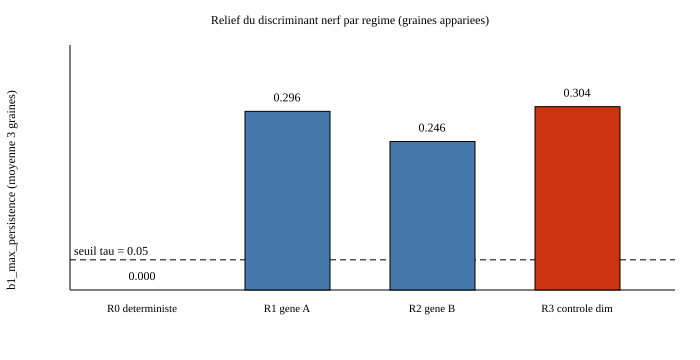

Barplot : R1 et R2 (bleu) = generateurs de nouveaute ; R3 (rouge) = controle dimension.


In [7]:
var regimes = new Dictionary<string, Dictionary<int,double>>
{
    ["R0 replicateur-mutation (deterministe)"] = r0_b1,
    ["R1 generateur A (resemencement uniforme)"] = r1_b1,
    ["R2 generateur B (derive genomique)"] = r2_b1,
    ["R3 controle dimension-sans-nouveaute"] = r3_b1
};
Console.WriteLine($"{"regime",-42} | " + string.Join(" | ", SEEDS.Select(s => $"seed {s}")) + " |  moyenne |  ecart-type");
Console.WriteLine(new string('-', 100));
var means = new Dictionary<string,double>();
foreach (var entry in regimes)
{
    var values = SEEDS.Select(s => entry.Value[s]).ToArray();
    double mean = values.Average();
    double std = Math.Sqrt(values.Select(v => (v - mean) * (v - mean)).Average());
    means[entry.Key] = mean;
    Console.WriteLine($"{entry.Key,-42} | " + string.Join(" | ", values.Select(v => v.ToString("F4", CultureInfo.InvariantCulture).PadLeft(7))) + $" | {mean,7:F4} | {std,9:F4}");
}
var m_r0 = means["R0 replicateur-mutation (deterministe)"];
var m_r1 = means["R1 generateur A (resemencement uniforme)"];
var m_r2 = means["R2 generateur B (derive genomique)"];
var m_r3 = means["R3 controle dimension-sans-nouveaute"];

// Regle pre-enregistree (cellule d'en-tete) -- appliquee programmatiquement
string verdict = m_r3 > TAU ? "CONFONDU_AVEC_LA_DIMENSION" :
    m_r1 > TAU && m_r2 > TAU ? "ROBUSTE_AU_GENERATEUR" :
    (m_r1 > TAU) != (m_r2 > TAU) ? "ARTEFACT_DE_GENERATEUR" : "INCONCLUSIVE";
Console.WriteLine();
Console.WriteLine($"relief(R0) = {m_r0:F4} | relief(R1) = {m_r1:F4} | relief(R2) = {m_r2:F4} | relief(R3) = {m_r3:F4} | tau = {TAU}");
Console.WriteLine($"VERDICT (regle pre-enregistree) = {verdict}");

// Barplot in-situ : relief moyen par regime
var plotValues = new[] {m_r0, m_r1, m_r2, m_r3};
var plotNames = new[] {"R0 deterministe", "R1 gene A", "R2 gene B", "R3 controle dim"};
var plotColors = new[] {"#888888", "#4477aa", "#4477aa", "#cc3311"};
double ymax = Math.Max(TAU, plotValues.Max()) * 1.2;
var svg = new System.Text.StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='360' viewBox='0 0 700 360'>");
svg.Append("<rect width='700' height='360' fill='white'/><text x='350' y='24' text-anchor='middle'>Relief du discriminant nerf par regime (graines appariees)</text>");
svg.Append("<line x1='70' y1='290' x2='675' y2='290' stroke='black'/><line x1='70' y1='45' x2='70' y2='290' stroke='black'/>");
double thresholdY = 290 - 220 * TAU / ymax;
svg.Append(FormattableString.Invariant($"<line x1='70' y1='{thresholdY}' x2='675' y2='{thresholdY}' stroke='black' stroke-dasharray='6,4'/><text x='74' y='{thresholdY - 5}'>seuil tau = {TAU}</text>"));
for (int i = 0; i < 4; i++)
{
    double x = 100 + 145 * i, height = 220 * plotValues[i] / ymax;
    svg.Append(FormattableString.Invariant($"<rect x='{x}' y='{290-height}' width='85' height='{height}' fill='{plotColors[i]}' stroke='black'/><text x='{x+42}' y='{280-height}' text-anchor='middle'>{plotValues[i]:F3}</text><text x='{x+42}' y='312' text-anchor='middle' font-size='11'>{plotNames[i]}</text>"));
}
svg.Append("<text x='15' y='190' transform='rotate(-90 15 190)' text-anchor='middle'>b1_max_persistence (moyenne 3 graines)</text></svg>");
// backend Agg (cell. 1) : show() non interactif -> UserWarning superflu
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<System.Text.StringBuilder>((value, writer) => writer.Write(value.ToString()), "image/svg+xml");
display(svg, "image/svg+xml");
Console.WriteLine("Barplot : R1 et R2 (bleu) = generateurs de nouveaute ; R3 (rouge) = controle dimension.");

### Lecture du verdict

Le verdict calculé ci-dessus applique la règle pré-enregistrée aux moyennes mesurées. Si le contrôle R3 dépasse le seuil, le relief ne distingue pas la nouveauté stratégique du contrôle de dimension dans cette expérience.

La démonstration interleaved établit l'égalité bit à bit des séries de coopération de R1 et de R3-interleaved pour la graine testée. Elle ne constitue pas un contrôle indépendant : le régime par blocs est utilisé pour ce contrôle.

La source Python et ce carnet utilisent des générateurs aléatoires différents ; les trajectoires et leurs agrégats ne sont donc pas identiques. La comparaison numérique doit également tenir compte des différences de recette observable : les résultats affichés ici ne constituent pas une attestation de parité avec la source. Aucune promotion en loi générale ne découle de cette expérience.

> **Exercice 1** (null de permutation). Le verdict dit que le relief accompagne la
> stochasticité, pas la trajectoire elle-même. Testez : permutez aléatoirement la série de
> coopération de R1 (structure temporelle détruite, distribution conservée) et mesurez
> `b1_max_persistence` sur 5 permutations. Si les valeurs restent dans la plage des régimes
> agent-based, le discriminant lit-il un *contenu* de trajectoire ou une *statistique
> de distribution* ?

In [8]:
// Exercice 1 -- a completer.
// Indice : coop = regime_r1(20260720) ; puis pour k de 0 à 4 :
//   perm = permutation des indices de coop ; mesurer coop_to_b1 sur la série permutée.
// Etape 1 : construire le generateur de permutations (distinct de celui de R1).
// Etape 2 : mesurer les 5 b1 et les comparer a r1_b1[20260720].
// Etape 3 : conclure en une phrase -- le discriminant lit-il la trajectoire ou la distribution ?
// TODO étudiant : compléter la mesure et l'interprétation.
double[] exercice1() => Array.Empty<double>();

> **Exercice 2** (le relief du contrôle suit-il le taux de turnover ?). Si le relief de R3
> vient du turnover stochastique, il devrait répondre au taux de mutation. Recalculez R3
> (blocs) avec `MU = 0.01` puis `MU = 0.10` sur la graine 20260720 et comparez les trois
> `b1_max_persistence`. Attention à garder l'appariement : ne changez QUE `MU`.

In [9]:
// Exercice 2 -- a completer.
// Indice : copier regime_r3 en parametrant MU (argument mu=...), ne rien changer d'autre.
// Etape 1 : mesurer b1 pour mu dans [0.01, 0.05, 0.10] sur la graine 20260720.
// Etape 2 : le relief croit-il avec le taux de turnover ?
// TODO étudiant : construire et comparer les mesures.
double[] exercice2() => Array.Empty<double>();

> **Exercice 3** (génomes memory-2 : plus de dimension, plus de nouveauté possible).
> Le générateur B ouvre 32 comportements (5 bits). Un génome memory-2 — réaction aux deux
> derniers coups de chaque joueur, 16 états + coup initial = 17 bits, 131 072 comportements —
> rend l'espace presque infini. Implémentez la lecture du génome memory-2 (la mutation reste
> un bit par mutant) et mesurez R2-memory-2 sur la graine 20260720. Le verdict change-t-il ?
> On attend honnêtement : non — le contrôle R3 prédit que la dimension n'est pas le bon axe.

In [10]:
// Exercice 3 -- a completer.
// Indice : genome = [init] + 16 bits d'index (own1,opp1,own0,opp0) ; l'index de reaction
//   est base 4 sur les deux derniers coups. Garder POP, GENS, ROUNDS, NOISE, MU apparies.
// Etape 1 : ecrire genome_play_2 (lecture a deux pas d'historique).
// Etape 2 : reutiliser la boucle de regime_r2 avec ce genome (population initiale : les
//   5 classiques transcrits en memory-2).
// Etape 3 : mesurer b1 et comparer a r2_b1[20260720] et a m_r3.
// TODO étudiant : définir la lecture et la simulation memory-2.
int genome_play_2(int[] genome, int[] own, int[] opp) => 0;

## Vérifiez votre compréhension

1. Dans le tableau C# ci-dessus, comparez les reliefs moyens de R0, R1, R2 et R3 au seuil `tau = 0.05`. Pourquoi le relief de R3, qui ne crée pas de comportement nouveau, met-il en difficulté la lecture « le relief mesure la nouveauté » ?
2. Reconstruisez le raisonnement qui mène du tableau au verdict calculé. Pourquoi la règle porte-t-elle sur les moyennes plutôt que sur une seule graine ?
3. Le contrôle R3 utilise la même stochasticité de population finie sans comportements nouveaux. Si l'on doublait sa taille de population, quelles quantités du tableau devraient bouger pour que le verdict change ? Pourquoi le protocole s'en remet-il à une règle pré-enregistrée plutôt qu'à cette intuition ?

Les moyennes Python sont respectivement `0.0000`, `0.3507`, `0.4096` et `0.3522`. Les générateurs aléatoires et la recette observable de ce carnet diffèrent de ceux de la source : les écarts ne sont donc pas attribuables au seul tirage.

## À retenir

| régime | mécanisme | lecture |
|---|---|---|
| R0 | réplicateur-mutation déterministe | relief nul dans cette exécution |
| R1 | générateur A (catalogue fermé) | relief au-dessus du seuil |
| R2 | générateur B (dérive génomique) | comparer la moyenne calculée au seuil |
| R3 | dimension sans nouveauté | le contrôle dépasse lui aussi le seuil |

La règle pré-enregistrée donne ici `CONFONDU_AVEC_LA_DIMENSION` : le contrôle R3 dépasse le seuil. Dans cette expérience, ce contrôle ne permet donc pas d'attribuer le relief observé à la seule apparition de nouveaux comportements. Ce résultat ne démontre pas à lui seul que la stochasticité de population finie est la cause du relief.

Les moyennes de la source Python sont différentes : environ 0,35 pour R1, 0,41 pour R2 et 0,35 pour R3. Les générateurs aléatoires et la recette observable diffèrent ; ces résultats C# ne constituent pas une attestation de parité numérique avec la source.

**Raccord** : ICT-15j mesure, ICT-15l audite la mesure. Une validation externe et un observable plus fin restent nécessaires avant toute généralisation.

## Références

- Protocole de contrôle de générateur : issue [#13308](https://github.com/jsboige/CoursIA/issues/13308) ; observatoire externe : issue [#13303](https://github.com/jsboige/CoursIA/issues/13303) ; substrat Axelrod régénéré : issue [#12673](https://github.com/jsboige/CoursIA/issues/12673).
- Discriminant d’origine : [ICT-15j](./ICT-15j-NerveDiscriminant-Python.ipynb) ; application au détecteur d’humour : issue #13306. Campagne multi-annotateurs : issue #12756.

## Attestation de parité — comparaison des sorties enregistrées

La comparaison porte sur les sorties affichées à quatre décimales. Les écarts ci-dessous sont calculés comme C# moins Python à partir de ces valeurs arrondies ; ils peuvent différer d'une unité au dernier chiffre d'un calcul effectué avant arrondi.

| Section | Comparaison mesurée |
|---|---|
| Protocole | Les paramètres et les trois graines affichés sont identiques. |
| R0 | Les trois reliefs affichés sont `0.0000` dans les deux carnets : écart affiché `0.0000` pour chaque graine. |
| R1 | Pour les graines 20260720, 42 et 7 : Python `0.3989`, `0.2583`, `0.3949` ; C# `0.4147`, `0.2264`, `0.2468` ; écarts `+0.0158`, `-0.0319`, `-0.1481`. Moyennes affichées : `0.3507` et `0.2960`, soit `-0.0547`. |
| R2 | Pour les mêmes graines : Python `0.3397`, `0.6957`, `0.1934` ; C# `0.2025`, `0.3533`, `0.1821` ; écarts `-0.1372`, `-0.3424`, `-0.0113`. Moyennes affichées : `0.4096` et `0.2460`, soit `-0.1636`. Les nombres de comportements nouveaux sont respectivement `26, 27, 27` et `27, 27, 27`. |
| R3 | Pour les mêmes graines : Python `0.3531`, `0.2411`, `0.4624` ; C# `0.3345`, `0.2772`, `0.2994` ; écarts `-0.0186`, `+0.0361`, `-0.1630`. Moyennes affichées : `0.3522` et `0.3037`, soit `-0.0485`. Les deux démonstrations interleaved affichent `True` dans les deux carnets. |
| Verdict | `CONFONDU_AVEC_LA_DIMENSION` dans les deux exécutions. |

La précision d'affichage est de `0.0001` : elle permet de comparer les résultats déterministes affichés, mais ne constitue pas une tolérance statistique pour les trajectoires. Le générateur C# seedé diffère de NumPy ; les écarts des régimes stochastiques ne sont donc pas des erreurs d'arrondi. La correspondance de la recette observable n'a pas été vérifiée sur des entrées communes : l'accord du verdict ne suffit pas à attester la parité numérique ou algorithmique. Le tableau documente les écarts mesurés, sans les déclarer conformes à une tolérance non établie.

## Pour aller plus loin

- Le discriminant audité : [ICT-15j — nerf discriminant](ICT-15j-NerveDiscriminant-Python.ipynb).
- **Jumeau Python** → [ICT-15l-IndependanceGenerateur-Python](ICT-15l-IndependanceGenerateur-Python.ipynb) — le carnet d'origine, en Python.
- Les suites nommées par le raccord : campagne multi-annotateurs #12756, observatoire externe #13303, détecteur d'humour #13306.
- Revenir au [cadrage de la série](../ICT-0-Framing.md).